In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.base import clone

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)

In [ ]:
dbts1 = pd.read_csv('/content/diabetic_data.csv')

In [ ]:
data = dbts1.copy()

print(data.shape)
data.head()

(101766, 50)


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),?,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),?,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 50 columns):
 #   Column                    Non-Null Count   Dtype 
---  ------                    --------------   ----- 
 0   encounter_id              101766 non-null  int64 
 1   patient_nbr               101766 non-null  int64 
 2   race                      101766 non-null  object
 3   gender                    101766 non-null  object
 4   age                       101766 non-null  object
 5   weight                    101766 non-null  object
 6   admission_type_id         101766 non-null  int64 
 7   discharge_disposition_id  101766 non-null  int64 
 8   admission_source_id       101766 non-null  int64 
 9   time_in_hospital          101766 non-null  int64 
 10  payer_code                101766 non-null  object
 11  medical_specialty         101766 non-null  object
 12  num_lab_procedures        101766 non-null  int64 
 13  num_procedures            101766 non-null  int64 
 14  num_

In [ ]:
print(data['readmitted'].value_counts())

readmitted
NO     54864
>30    35545
<30    11357
Name: count, dtype: int64


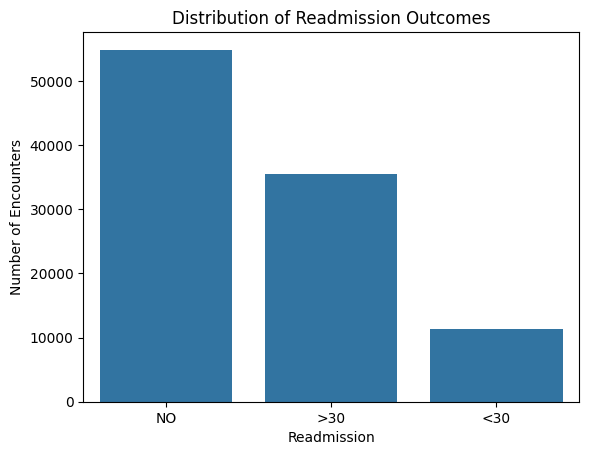

In [ ]:
sns.countplot(data=data, x='readmitted')

plt.title('Distribution of Readmission Outcomes')
plt.xlabel('Readmission')
plt.ylabel('Number of Encounters')
plt.show()

In [ ]:
# The dataset uses ? for missing values. Keeping missing categories for now.
data.replace('?', np.nan, inplace=True)

missing = pd.DataFrame({
    'Count': data.isnull().sum(),
    'Percentage': data.isnull().mean() * 100
})

missing = missing[missing['Count'] > 0]
missing.sort_values('Percentage', ascending=False)

,Count,Percentage
weight,98569,96.858479
max_glu_serum,96420,94.746772
A1Cresult,84748,83.277322
medical_specialty,49949,49.082208
payer_code,40256,39.557416
race,2273,2.233555
diag_3,1423,1.398306
diag_2,358,0.351787
diag_1,21,0.020636


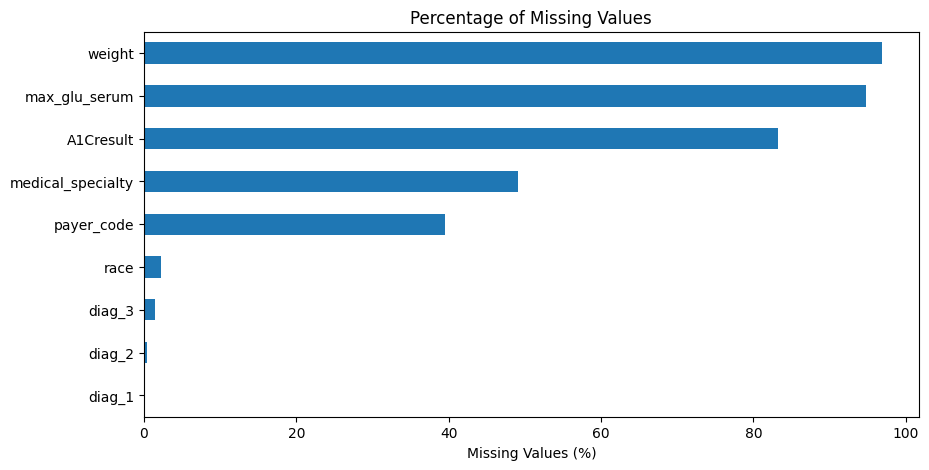

In [ ]:
missing['Percentage'].sort_values().plot(
    kind='barh',
    figsize=(10, 5)
)

plt.title('Percentage of Missing Values')
plt.xlabel('Missing Values (%)')
plt.show()

In [ ]:
print('Duplicate rows:', data.duplicated().sum())

data = data.drop_duplicates()

Duplicate rows: 0


In [ ]:
print('Unique encounters:', data['encounter_id'].nunique())
print('Unique patients:', data['patient_nbr'].nunique())

Unique encounters: 101766
Unique patients: 71518


In [ ]:
# Only readmissions in less than 30 days count as a positive outcome.
data = data.dropna(subset=['readmitted', 'patient_nbr'])

data['readmitted_30'] = (
    data['readmitted'] == '<30'
).astype(int)

data['readmitted_30'].value_counts()

,count
readmitted_30,
0,90409
1,11357


In [ ]:
data['readmitted_30'].value_counts(normalize=True) * 100

,proportion
readmitted_30,
0,88.840084
1,11.159916


In [ ]:
# Starting with these 14 features for the initial experiments.
# We can include diagnosis codes and other medications later.
numerical_features = [
    'time_in_hospital',
    'num_lab_procedures',
    'num_procedures',
    'num_medications',
    'number_outpatient',
    'number_emergency',
    'number_inpatient',
    'number_diagnoses'
]

categorical_features = [
    'age',
    'gender',
    'race',
    'insulin',
    'diabetesMed',
    'change'
]

features = numerical_features + categorical_features

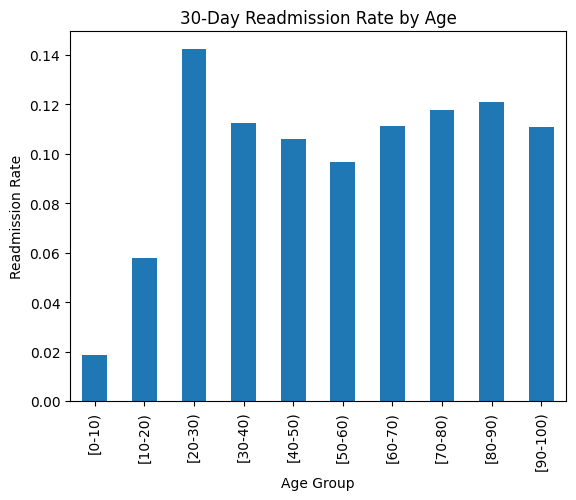

In [ ]:
# Checked how readmission rates differ across age groups.
# Could add more categories as per the experiments.
age_readmission = data.groupby('age')['readmitted_30'].mean()

age_readmission.plot(kind='bar')

plt.title('30-Day Readmission Rate by Age')
plt.ylabel('Readmission Rate')
plt.xlabel('Age Group')
plt.show()

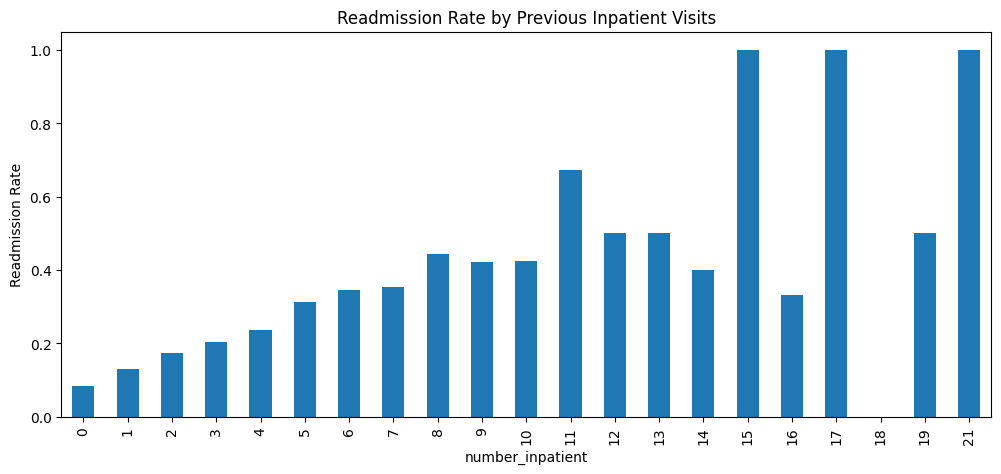

In [ ]:
# Looking at previous inpatient visits as a possible predictor of readmission.
inpatient_readmission = data.groupby('number_inpatient')['readmitted_30'].mean()

inpatient_readmission.plot(kind='bar', figsize=(12, 5))

plt.title('Readmission Rate by Previous Inpatient Visits')
plt.ylabel('Readmission Rate')
plt.show()

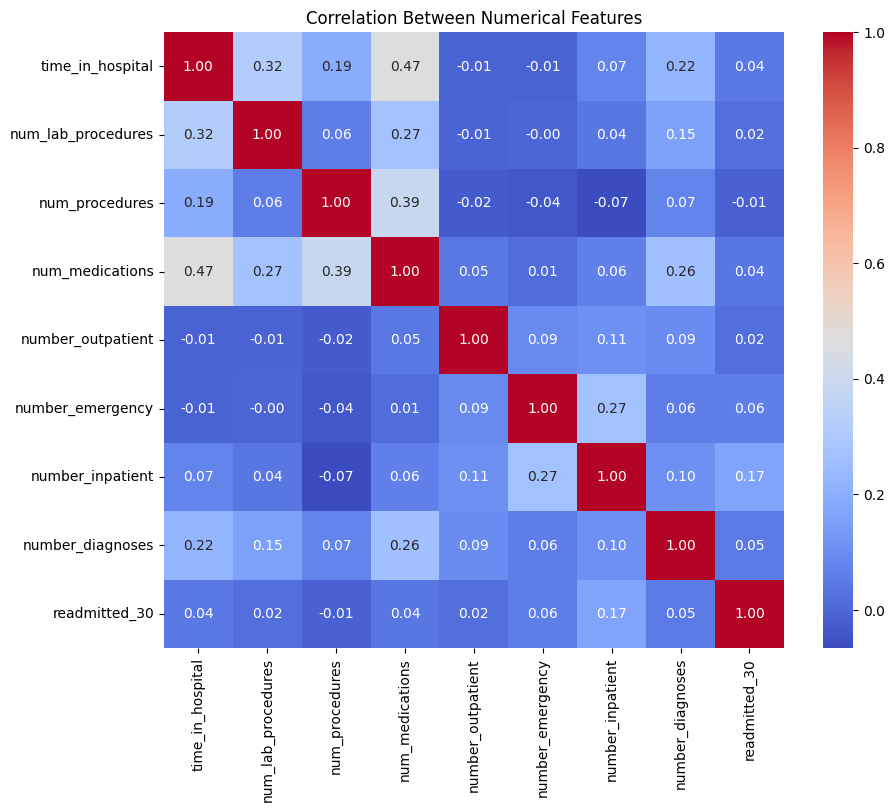

In [ ]:
correlation = data[
    numerical_features + ['readmitted_30']
].corr()

plt.figure(figsize=(10, 8))

sns.heatmap(
    correlation,
    annot=True,
    fmt='.2f',
    cmap='coolwarm'
)

plt.title('Correlation Between Numerical Features')
plt.show()

In [ ]:
X = data[features]
y = data['readmitted_30']
groups = data['patient_nbr']

print(X.shape)
print(y.shape)

(101766, 14)
(101766,)


In [ ]:
# Split by patient rather than encounter to avoid data leakage.
# Keeping 20% of the patients aside for final testing.
split = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_val_idx, test_idx = next(
    split.split(X, y, groups)
)

X_train_val = X.iloc[train_val_idx]
y_train_val = y.iloc[train_val_idx]

X_test = X.iloc[test_idx]
y_test = y.iloc[test_idx]

In [ ]:
# Roughly 60/20/20 overall split by patient. Using validation for the initial experiments.
split2 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.25,
    random_state=42
)

train_idx, val_idx = next(
    split2.split(
        X_train_val,
        y_train_val,
        groups.iloc[train_val_idx]
    )
)

X_train = X_train_val.iloc[train_idx]
y_train = y_train_val.iloc[train_idx]

X_val = X_train_val.iloc[val_idx]
y_val = y_train_val.iloc[val_idx]

In [ ]:
print('Training:', X_train.shape)
print('Validation:', X_val.shape)
print('Testing:', X_test.shape)

Training: (60988, 14)
Validation: (20625, 14)
Testing: (20153, 14)


In [ ]:
# Used median imputation here since some numerical features are skewed.
numerical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

In [ ]:
# Keeping missing categories as Unknown rather than dropping those records.
categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(
        strategy='constant',
        fill_value='Unknown'
    )),
    ('encoder', OneHotEncoder(
        handle_unknown='ignore'
    ))
])

In [ ]:
preprocessor = ColumnTransformer([
    ('num', numerical_pipeline, numerical_features),
    ('cat', categorical_pipeline, categorical_features)
])

In [ ]:
# Experiment 1: Dummy classifier as the baseline for the other two models.
# Kept the random forest small for the initial pipeline.
models = {
    'Dummy Classifier': DummyClassifier(
        strategy='most_frequent'
    ),

    'Logistic Regression': LogisticRegression(
        max_iter=1000
    ),

    'Random Forest': RandomForestClassifier(
        n_estimators=50,
        max_depth=10,
        random_state=42
    )
}

In [ ]:
trained_models = {}

for name, model in models.items():
    pipeline = Pipeline([
        ('preprocessing', clone(preprocessor)),
        ('model', model)
    ])

    pipeline.fit(X_train, y_train)
    trained_models[name] = pipeline

    print(name, 'trained successfully')

Dummy Classifier trained successfully
Logistic Regression trained successfully
Random Forest trained successfully


In [ ]:
# Using the same validation set for all models. Accuracy alone may be misleading.
results = []

for name, model in trained_models.items():
    predictions = model.predict(X_val)
    probabilities = model.predict_proba(X_val)[:, 1]

    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_val, predictions),
        'Precision': precision_score(y_val, predictions, zero_division=0),
        'Recall': recall_score(y_val, predictions, zero_division=0),
        'F1 Score': f1_score(y_val, predictions, zero_division=0),
        'ROC AUC': roc_auc_score(y_val, probabilities),
        'Average Precision': average_precision_score(y_val, probabilities)
    })

results_df = pd.DataFrame(results)
results_df.round(3)

,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC,Average Precision
0,Dummy Classifier,0.885,0.000,0.000,0.000,0.500,0.115
1,Logistic Regression,0.886,0.523,0.019,0.038,0.631,0.199
2,Random Forest,0.885,0.500,0.000,0.001,0.634,0.198


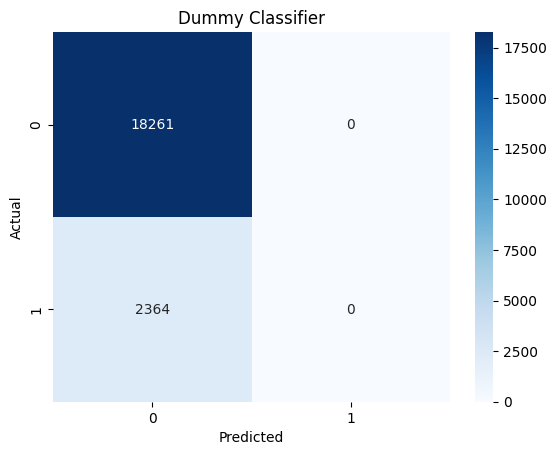

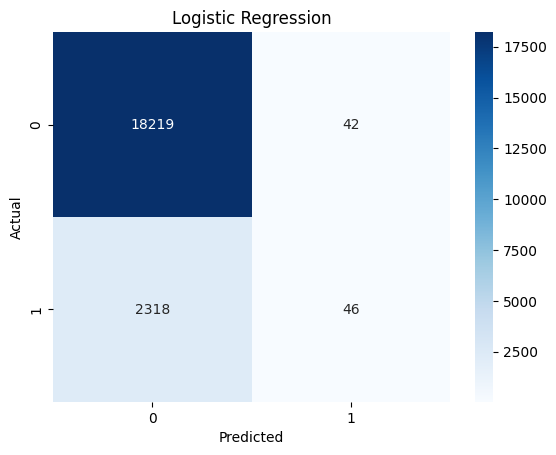

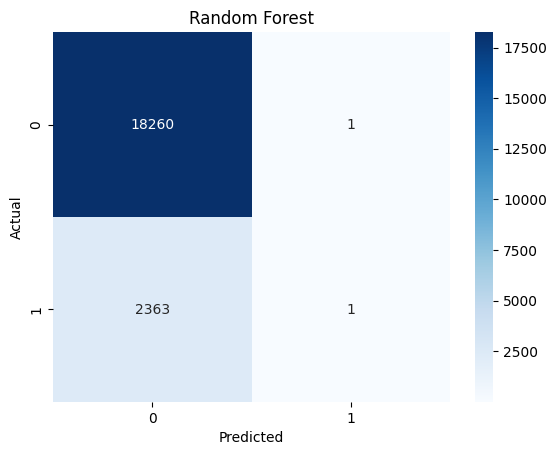

In [ ]:
for name, model in trained_models.items():
    predictions = model.predict(X_val)
    cm = confusion_matrix(y_val, predictions)

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues'
    )

    plt.title(name)
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.show()

In [ ]:
# Experiment 2: Using built-in feature importance for now.
# Can add SHAP/LIME later for a more detailed interpretation.
rf_pipeline = trained_models['Random Forest']
rf_model = rf_pipeline.named_steps['model']

feature_names = rf_pipeline.named_steps['preprocessing'].get_feature_names_out()

importance = pd.Series(
    rf_model.feature_importances_,
    index=feature_names
)

importance = importance.sort_values(ascending=False)
importance.head(10)

,0
num__number_inpatient,0.291696
num__num_lab_procedures,0.105654
num__num_medications,0.091468
num__time_in_hospital,0.073518
num__number_emergency,0.072238
num__number_diagnoses,0.057024
num__num_procedures,0.041972
num__number_outpatient,0.041293
cat__gender_Male,0.014095
cat__gender_Female,0.012658


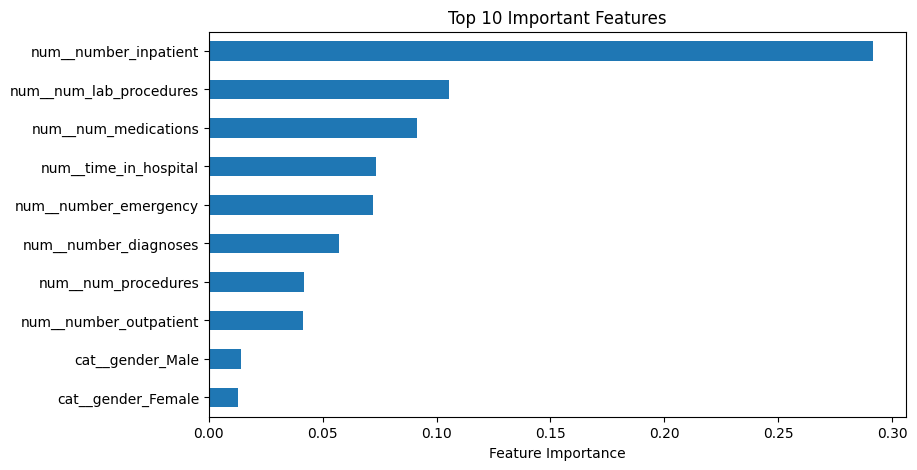

In [ ]:
importance.head(10).sort_values().plot(
    kind='barh',
    figsize=(9, 5)
)

plt.title('Top 10 Important Features')
plt.xlabel('Feature Importance')
plt.show()

In [ ]:
# Experiment 3: Comparing class weighting with the original logistic regression.
# Mainly interested in the trade-off between recall and precision.
balanced_lr = Pipeline([
    ('preprocessing', clone(preprocessor)),
    ('model', LogisticRegression(
        max_iter=1000,
        class_weight='balanced'
    ))
])

balanced_lr.fit(X_train, y_train)

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['time_in_hospital',
                                                   'num_lab_procedures',
                                                   'num_procedures',
                                                   'num_medications',
                                                   'number_outpatient',
                                                   'number_emergency',
                                                   'number_inpatient',
                                                   'number_diagnoses']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value='Unknown',
                                                                                 strategy='constant')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['age', 'gender', 'race',
                                                   'insulin', 'diabetesMed',
                                                   'change'])])),
                ('model',
                 LogisticRegression(class_weight='balanced', max_iter=1000))])

In [ ]:
imbalance_models = {
    'Regular LR': trained_models['Logistic Regression'],
    'Balanced LR': balanced_lr
}

imbalance_results = []

for name, model in imbalance_models.items():
    predictions = model.predict(X_val)

    imbalance_results.append({
        'Model': name,
        'Precision': precision_score(y_val, predictions, zero_division=0),
        'Recall': recall_score(y_val, predictions, zero_division=0),
        'F1 Score': f1_score(y_val, predictions, zero_division=0)
    })

pd.DataFrame(imbalance_results).round(3)

,Model,Precision,Recall,F1 Score
0,Regular LR,0.523,0.019,0.038
1,Balanced LR,0.168,0.489,0.250
